# Revisited Analysis: Leakage-Free Results with Baselines

This notebook re-examines the original course project (`app_classification.ipynb`) after it was submitted.
It fixes two problems in the original evaluation:

1. **Target leakage in Task 1.** The original feature set included `Price`. An app is *Paid* exactly when its price is above zero, and Task 1b predicts price itself, so Task 1 models were given the answer as an input. That is why they scored a perfect 1.000.
2. **No baselines.** Most apps are *Free* (93%) and most are *Not Recommended* (about 80%), so a model that always predicts the majority class already scores high accuracy. Every model here is compared against that baseline, using metrics that account for class imbalance.

It also changes how missing ratings are handled in Task 2: instead of filling them with the median (which silently labels them *Not Recommended*), apps without a rating are dropped from that task, since their true label is unknown.

**Features used:** only information available when an app launches: `Size`, `Category`, `Content Rating` and `Genres`. `Price` is also kept for Task 2, where it is a legitimate input.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             mean_absolute_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

RANDOM_STATE = 42

## 1. Load and preprocess
Same cleaning steps as the original notebook, except that missing ratings are kept as missing.

In [2]:
df = pd.read_csv('data/googleplaystore.csv')

df = df.drop(columns=[c for c in ['Unnamed: 0', 'App', 'Last Updated', 'Current Ver', 'Android Ver'] if c in df.columns])
df = df[df['Type'].isin(['Free', 'Paid'])].drop_duplicates()

df['Price'] = pd.to_numeric(df['Price'].astype(str).str.replace('$', '', regex=False), errors='coerce').fillna(0)

def clean_size(s):
    s = str(s)
    if s.endswith('M'): return float(s[:-1])
    if s.endswith('k'): return float(s[:-1]) / 1024
    return np.nan

df['Size'] = df['Size'].apply(clean_size)
df['Size'] = df['Size'].fillna(df['Size'].median())
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')   # missing ratings stay missing

df = pd.get_dummies(df, columns=['Category', 'Content Rating', 'Genres'])
cat_cols = [c for c in df.columns if c.startswith(('Category_', 'Content Rating_', 'Genres_'))]

print('Apps:', len(df))
print('Missing ratings:', df['Rating'].isna().sum())

Apps: 10300
Missing ratings: 1412


## 2. Evaluation helpers
For imbalanced classification, accuracy alone is misleading. Each model is reported with:
- **Balanced accuracy:** the average recall across both classes (0.5 = no better than guessing)
- **Precision, recall and F1 for the minority class** (*Paid* or *Recommended*), which is the class we actually care about finding
- **ROC-AUC (area under the receiver operating characteristic curve):** how well the model ranks positives above negatives (0.5 = random)

In [3]:
def classification_table(models, X_train, X_test, y_train, y_test):
    rows = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        proba = model.predict_proba(X_test)[:, 1]
        rows[name] = {
            'Accuracy': accuracy_score(y_test, pred),
            'Balanced acc.': balanced_accuracy_score(y_test, pred),
            'Precision (minority)': precision_score(y_test, pred, zero_division=0),
            'Recall (minority)': recall_score(y_test, pred, zero_division=0),
            'F1 (minority)': f1_score(y_test, pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y_test, proba),
        }
    return pd.DataFrame(rows).T.round(4)

def classifiers(pos_weight):
    return {
        'Baseline (majority class)': DummyClassifier(strategy='most_frequent'),
        'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
        'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                                 scale_pos_weight=pos_weight, eval_metric='logloss',
                                 random_state=RANDOM_STATE),
    }

## 3. Task 1a: Free vs Paid, without Price
Class weights are balanced so models are not rewarded for always predicting *Free*. The split is stratified so both sets keep the same Free/Paid ratio.

In [4]:
X1 = df[['Size'] + cat_cols]
y1 = (df['Type'] == 'Paid').astype(int)
print(y1.value_counts(normalize=True).round(3))

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, stratify=y1, random_state=RANDOM_STATE)

pos_weight_1 = (y1_train == 0).sum() / (y1_train == 1).sum()
task1a = classification_table(classifiers(pos_weight_1), X1_train, X1_test, y1_train, y1_test)
task1a

Type
0    0.926
1    0.074
Name: proportion, dtype: float64


,Accuracy,Balanced acc.,Precision (minority),Recall (minority),F1 (minority),ROC-AUC
Baseline (majority class),0.9257,0.5000,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.6549,0.6693,0.1367,0.6863,0.2280,0.7161
Random Forest,0.7646,0.6324,0.1527,0.4771,0.2314,0.6985
XGBoost,0.7553,0.6815,0.1707,0.5948,0.2653,0.7121


## 4. Task 1b: Price of paid apps, without Price as an input
Prices are heavily skewed (most are $0.99 to $4.99, a few are $400), so models predict **log(price)**, and errors are reported back in dollars. The baseline always predicts the median price.

In [5]:
paid = df[df['Type'] == 'Paid']
X2 = paid[['Size'] + cat_cols]
y2 = paid['Price']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=RANDOM_STATE)

regressors = {
    'Baseline (median price)': DummyRegressor(strategy='median'),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                           random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                            random_state=RANDOM_STATE),
}

rows = {}
for name, model in regressors.items():
    model.fit(X2_train, np.log1p(y2_train))
    pred = np.expm1(model.predict(X2_test))
    rows[name] = {
        'MAE ($)': mean_absolute_error(y2_test, pred),
        'Median abs. error ($)': np.median(np.abs(y2_test - pred)),
        'R2': r2_score(y2_test, pred),
    }
task1b = pd.DataFrame(rows).T.round(4)
task1b

,MAE ($),Median abs. error ($),R2
Baseline (median price),10.3297,1.5000,-0.0272
Ridge Regression,10.0757,1.3092,0.0677
Random Forest,10.6156,1.5293,0.0468
XGBoost,9.8289,1.5183,0.1791


## 5. Task 2: Recommended (rating above 4.5)
Apps with no rating are excluded, since their true label is unknown. `Price` is a legitimate launch-time input here, so it is kept.

In [6]:
rated = df[df['Rating'].notna()]
X3 = rated[['Size', 'Price'] + cat_cols]
y3 = (rated['Rating'] > 4.5).astype(int)
print('Rated apps:', len(rated))
print(y3.value_counts(normalize=True).round(3))

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, stratify=y3, random_state=RANDOM_STATE)

pos_weight_3 = (y3_train == 0).sum() / (y3_train == 1).sum()
task2 = classification_table(classifiers(pos_weight_3), X3_train, X3_test, y3_train, y3_test)
task2

Rated apps: 8888
Rating
0    0.793
1    0.207
Name: proportion, dtype: float64


,Accuracy,Balanced acc.,Precision (minority),Recall (minority),F1 (minority),ROC-AUC
Baseline (majority class),0.7930,0.5000,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.6119,0.6218,0.2967,0.6386,0.4052,0.6577
Random Forest,0.6502,0.6067,0.3034,0.5326,0.3866,0.6669
XGBoost,0.6451,0.6447,0.3216,0.6440,0.4290,0.6904


## 6. Summary chart

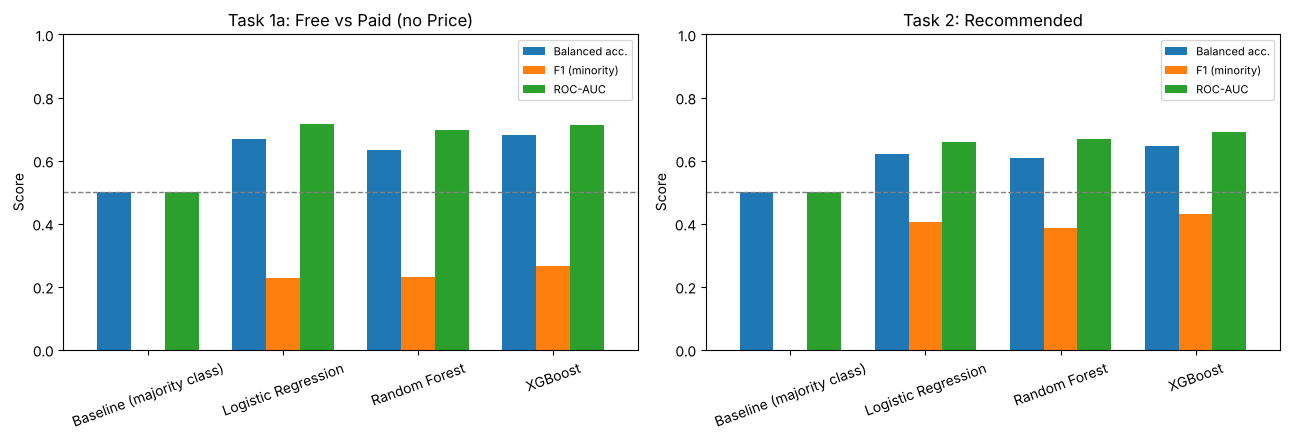

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (title, table) in zip(axes, [('Task 1a: Free vs Paid (no Price)', task1a),
                                     ('Task 2: Recommended', task2)]):
    table[['Balanced acc.', 'F1 (minority)', 'ROC-AUC']].plot(kind='bar', ax=ax, width=0.75)
    ax.axhline(0.5, color='grey', linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Score')
    ax.tick_params(axis='x', rotation=20)
    ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig('images/revisited_results.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Findings

- **Task 1a has weak but real signal.** Without `Price`, the best model (XGBoost) reaches a balanced accuracy of about 0.68 and ROC-AUC of about 0.71, well above the baseline's 0.5. But precision on paid apps stays below 0.2, so most apps flagged as *Paid* are actually free. Size, category and genre alone are weak predictors of whether an app charges money, far from the perfect 1.000 originally reported.
- **Price prediction barely improves on guessing.** The best model (XGBoost) cuts mean absolute error only from about $10.33 to $9.83 versus always predicting the median price, with R² around 0.18, and the typical (median) error stays around $1.50 for every model. The original R² of 1.000 came entirely from the leaked input.
- **Task 2 has modest real signal.** The original Logistic Regression's accuracy (0.8097) matched the majority-class baseline exactly, because it never predicted a recommended app. With balanced weights, XGBoost finds about 64% of highly rated apps with ROC-AUC around 0.69, though precision is only about 0.32.
- **Takeaway:** app success on the Play Store is driven mostly by things this dataset doesn't capture before launch (quality, marketing, developer reputation). The most useful result of this project is the evaluation lesson: always check for target leakage and compare against a baseline before trusting a high score.